# T4.1 Observational reference, part b: L1 uncertainty and signal-to-noise

**Purpose** (Table 4.2, D-5 validation plan): using the data collected in DATA-2, we repeat the analyses of the reference simulation, but now adapted to
real observations, for the section of the swath that the reference simulation shares with DATA-2.

**Implementation**
1. Estimate L1 noise for the reference simulation
2. Estimate L1 noise for the DATA-2 case studies
3. Compare steps 1. and 2.
4. Compare step 2. with the TSC signal from DATA-2

**Requirements**: reference simulation SWB-SCA, DATA-2 prepared in `T4.1a_DATA-2_preparation.ipynb`

The scenes go through the L1 chain of `SCA_uncertainty___monte_carlo_California.ipynb`. Each date uses its own random seed, so the spread across dates
also contains the spread across noise realisations. The reference simulation (California) is restricted to the ground-range band of DATA-2 and run with the same seeds.

This notebook performs the test and reports the results for interpretation. No tolerances or pass/fail criteria are applied.

In [1]:
import os
import glob
import numpy as np
import xarray as xr
import pandas as pd
from tqdm import tqdm
from matplotlib import pyplot as plt

from sca_module.readers import create_dataset
from sca_module.dopsca_setup import DopSCAConfig
from leakage.conversions import dop2vel
from sca_module.simulate_L1 import compute_cube_observation_geometry, compute_observations, create_observation_cube, compute_lpf_cube, add_L1_uncertainties, multilook_nrcs_to_grid, combine_pulse_pair, correct_lag_product_leakage

func_rmse = lambda x, rounding=3:  np.round(np.sqrt(np.nanmean(x**2)), rounding)

plt.rcParams.update({'font.size': 10, 'font.weight' : 'bold'})

## 0 - Parameters

In [2]:
dir_prepared = '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/DATA-2/prepared_SCA/'
files_prepared = sorted(glob.glob(dir_prepared + 'DATA-2_Agulhas_*_SCA.nc'))
dates = [os.path.basename(f).split('_')[2] for f in files_prepared]

# one random seed per date, the reference simulation is run with the same seeds
seeds = dict(zip(dates, range(len(dates))))

files_cali = [
    '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_input_California.nc',
    '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_output_California.nc'
]

beam_SCA = xr.open_dataset('/Users/opodriscoll/Documents/projects/DopSCA MOMS/data/beam_pattern_updated.nc')['beam_sca']

## 1 - L1 uncertainty chain
The chain of `SCA_uncertainty___monte_carlo_California.ipynb`, for a scene holding `nrcs`, `dop` and `inc` (degrees) on (`az`, `grg`). Two additions, the signal:
- `V_current_lpf`: the input surface current (`dop` as surface velocity) low-pass filtered to 50 km on the input grid, without the beam: the geophysical reference;
- `V_pulse_rg_lpf`: the same current integrated over the beam per pulse (as the instrument sees it, without noise), then low-pass filtered: the signal the instrument delivers.

In [3]:
def compute_L1_uncertainty(scene, random_state):
    sca = DopSCAConfig()
    sca.random_state = random_state
    sca.Lambda = sca.get_wavelength()
    # The magic_divider is an unnecessary, but convenient, method to resample the input data to some common sampling.
    sca.grid_spacing_target = sca.get_grid_spacing_target(magic_divider=2)

    # Here we interpolate to finer grid spacing,
    new_az = np.arange(scene.az.min(), scene.az.max(), sca.grid_spacing_target)
    new_grg = np.arange(scene.grg.min(), scene.grg.max(), sca.grid_spacing_target)
    scene = scene.interp(az=new_az, grg=new_grg)

    data = create_dataset(
        nrcs=scene[sca.var_nrcs].transpose(sca.dim_az, sca.dim_range).data,
        dop=scene[sca.var_dop].transpose(sca.dim_az, sca.dim_range).data,
        inc=scene[sca.var_inc].transpose(sca.dim_az, sca.dim_range).data,
        grg=scene.grg.data,
        az=scene.az.data,
        grid_spacing=sca.grid_spacing_target,
    )

    data_cube = create_observation_cube(data, sca.az_footprint_cutoff, sca.grid_spacing_target, sca.v_sat_ground, sca.PRF, dropna=False).compute()
    data_cube = compute_cube_observation_geometry(data_cube, sca.dim_az_beam, sca.dim_az_slow_time, sca.dim_range, sca.var_inc, sca.z0, sca.boresight_elevation_angle_scat)

    data_cube = data_cube.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)
    data_cube['beam']= beam_SCA.interp(az_beam=data_cube.az_beam, grg=data_cube.grg, method='linear')

    data_cube = compute_observations(data_cube, sca.var_nrcs, sca.var_inc, sca.dim_az_beam, sca.v_sat_orbit, sca.Lambda, sca.T_pp, var_azimuth_angle_wrt_boresight = "az_angle_wrt_boresight_ground")
    data_cube = data_cube.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)

    ds = add_L1_uncertainties(
        ds = data_cube,
        dim_range = sca.dim_range,
        dim_az_beam = sca.dim_az_beam,
        v_sat_orbit = sca.v_sat_orbit,
        U = sca.U,
        sat_height = sca.z0,
        T_pp= sca.T_pp,
        Lambda = sca.Lambda,
        fixed_SCR=None, # < -------- here we let the SCR be calculated from the NRCS data
        grid_spacing_slant_range=sca.grid_spacing_slant_range_SCA,
        random_state=sca.random_state
    )

    # -- Resample to uniform ground-range spacing
    grg_uniform = np.arange(scene.grg.min(), scene.grg.max(), sca.grid_spacing_slant_range_SCA)
    ds = ds.interp(grg=grg_uniform, method=sca.interpolator).astype("float32")
    ds = ds.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)

    # -- Repeat the leakage estimation, but now using a realization of SCA's estimated NRCS
    data['nrcs_scat_speckle'] = multilook_nrcs_to_grid(ds, data)  # averaged along range over one grid cell, not point-sampled

    data_cube_ = create_observation_cube(data, sca.az_footprint_cutoff, sca.grid_spacing_target, sca.v_sat_ground, sca.PRF, dropna=False).compute()
    data_cube_ = compute_cube_observation_geometry(data_cube_, sca.dim_az_beam, sca.dim_az_slow_time, sca.dim_range, sca.var_inc, sca.z0, sca.boresight_elevation_angle_scat)

    data_cube_ = data_cube_.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)
    data_cube_['beam']= beam_SCA.interp(az_beam=data_cube_.az_beam, grg=data_cube_.grg, method='linear')

    # here we use 'nrcs_scat_speckle' as the input NRCS, rather than the noise-free version
    data_cube_ = compute_observations(data_cube_, 'nrcs_scat_speckle', sca.var_inc, sca.dim_az_beam, sca.v_sat_orbit, sca.Lambda, sca.T_pp, var_azimuth_angle_wrt_boresight = "az_angle_wrt_boresight_ground")
    data_cube_ = data_cube_.interp(grg=grg_uniform, method=sca.interpolator).astype("float32")
    data_cube_ = data_cube_.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)

    mask_2 = data_cube_["V_leakage_pulse_rg"].notnull()
    ds_filt = data_cube_.where(mask_2, drop=True)

    ds['V_leakage_pulse_rg_net'] = - ds_filt['V_leakage_pulse_rg'] + ds['V_leakage_pulse_rg']

    assert len(set(np.diff(data_cube_.grg))) == 1, "ground range sampling is not continuous"

    # -- Low-pass filter to obtain L1 uncertainty and the surface-current signal at product resolution
    # leakage correction as a rotation of the lag products by minus the estimated leakage, before they are summed by the low-pass filter
    ds = correct_lag_product_leakage(ds, Lambda=sca.Lambda, T_pp=sca.T_pp)
    ds = compute_lpf_cube(
            ds,
            resolution_product= sca.resolution_product,
            fs_x=1 / ds.attrs["stride"],
            fs_y=1 / np.diff(data_cube_.grg)[0],
            data_2_lpf=["V_leakage_pulse_rg_net", "V_leakage_pulse_rg", "pp_re", "pp_im", "pp_re_sigma", "pp_im_sigma", "pp_re_sigma_net", "pp_im_sigma_net", "pp_re_signal_and_sigma", "pp_im_signal_and_sigma", "pp_re_signal_and_sigma_net", "pp_im_signal_and_sigma_net", "V_pulse_rg"],
            window=sca.product_averaging_window,
            crop_edges = True,
            min_footprint_coverage = 1, # only product cells whose whole footprint is available
        )

    # pulse-pair phase from the filtered lag products (summed as by the processor), V_sigma only after filtering
    ds = combine_pulse_pair(ds, Lambda=sca.Lambda, T_pp=sca.T_pp)                 # native resolution: V_pp, V_sigma(_net), V_signal_and_sigma(_net)
    ds = combine_pulse_pair(ds, Lambda=sca.Lambda, T_pp=sca.T_pp, suffix="_lpf")  # product resolution: V_pp_lpf, V_sigma(_net)_lpf, V_signal_and_sigma(_net)_lpf

    # -- Geophysical reference: the input surface current at 50 km on the input grid, without the beam, on the product cells
    data['V_current'] = dop2vel(Doppler=data['dop'], Lambda=sca.Lambda, angle_incidence=data['inc'], angle_azimuth=90, degrees=True)
    current = compute_lpf_cube(
            data[['V_current', 'dop']],
            resolution_product= sca.resolution_product,
            fs_x=1 / sca.grid_spacing_target,
            fs_y=1 / sca.grid_spacing_target,
            data_2_lpf=['V_current', 'dop'],
            window=sca.product_averaging_window,
            crop_edges = True,
            min_footprint_coverage = 1,
        )['V_current_lpf']
    ds['V_current_lpf'] = current.interp({sca.dim_az: ds[sca.dim_az_slow_time], sca.dim_range: ds[sca.dim_range]}).drop_vars(sca.dim_az, errors='ignore')

    # keep the product fields only, the beam dimension is large
    return ds[[name for name in ds.data_vars if sca.dim_az_beam not in ds[name].dims]]

The L1 noise is the leakage-corrected `V_sigma_net_lpf`, the signal the input surface current at 50 km `V_current_lpf`. For comparison, the std of the
beam-integrated current `V_pulse_rg_lpf` (the signal as the instrument transfers it) is also given. All are compared over the same product cells only:
those where all are available, i.e. whose whole 50 km footprint is available for each. SNR = std(signal) / RMS(L1 noise).

In [4]:
def shared_cells(ds):
    # product cells where the L1 noise and both surface currents are available
    return ds['V_sigma_net_lpf'].notnull() & ds['V_current_lpf'].notnull() & ds['V_pulse_rg_lpf'].notnull()

def summarise(ds):
    evaluate = shared_cells(ds)
    noise, signal = ds['V_sigma_net_lpf'].where(evaluate), ds['V_current_lpf'].where(evaluate)
    return {
        "L1 noise RMS [m/s]": func_rmse(noise),
        "TSC std [m/s]": float(signal.std()),
        "SNR": float(signal.std()) / func_rmse(noise, 6),
        "TSC std, beam-integrated [m/s]": float(ds['V_pulse_rg_lpf'].where(evaluate).std()),
    }

## 2 - Reference simulation: California over the ground-range band of DATA-2
The input Doppler is the SWB surface-current Doppler `tsc_dop`; the noise terms do not depend on it.

In [5]:
grg_data_2 = xr.open_dataset(files_prepared[0]).grg

sca = DopSCAConfig()
simulation = xr.open_mfdataset(files_cali, compat='no_conflicts', engine='netcdf4').sel(sat = 'S1').compute()
sca.magic_offset = sca.get_magic_offset(incidence_min=simulation.inc.min().data)

# clipping unreasonable incidence angles
simulation = simulation.sel(grg = slice(sca.grg_min - sca.magic_offset, sca.grg_max - sca.magic_offset))
simulation = simulation.assign_coords(grg = simulation.grg + sca.magic_offset)
simulation = simulation.interp(grg = grg_data_2.data)

scene_cali = xr.Dataset(
    {
        'nrcs': (('az', 'grg'), simulation[sca.var_nrcs].sel(pol='M').transpose('az', 'grg').data),
        'dop': (('az', 'grg'), simulation['tsc_dop'].transpose('az', 'grg').data),
        'inc': (('az', 'grg'), np.degrees(simulation[sca.var_inc]).broadcast_like(simulation['tsc_dop']).transpose('az', 'grg').data),
    },
    coords = dict(az = simulation.az.data, grg = simulation.grg.data),
)

In [6]:
summaries_cali = {}
for date, random_state in tqdm(seeds.items()):
    ds = compute_L1_uncertainty(scene_cali, random_state)
    summaries_cali[random_state] = summarise(ds)
    if random_state == 0:
        ds_cali = ds

  0%|          | 0/7 [00:00<?, ?it/s]

 14%|█▍        | 1/7 [00:03<00:22,  3.81s/it]

 29%|██▊       | 2/7 [00:07<00:17,  3.59s/it]

 43%|████▎     | 3/7 [00:10<00:14,  3.56s/it]

 57%|█████▋    | 4/7 [00:14<00:10,  3.49s/it]

 71%|███████▏  | 5/7 [00:17<00:06,  3.48s/it]

 86%|████████▌ | 6/7 [00:21<00:03,  3.56s/it]

100%|██████████| 7/7 [00:24<00:00,  3.53s/it]

100%|██████████| 7/7 [00:24<00:00,  3.54s/it]

## 3 - DATA-2: the seven Agulhas dates, each with its own seed

In [7]:
summaries_data_2, scenes, ds_data_2 = {}, {}, {}
for date, file in tqdm(zip(dates, files_prepared), total=len(dates)):
    scenes[date] = xr.open_dataset(file)[['nrcs', 'dop', 'inc']]
    ds_data_2[date] = compute_L1_uncertainty(scenes[date], seeds[date])
    summaries_data_2[date] = summarise(ds_data_2[date])

  0%|          | 0/7 [00:00<?, ?it/s]

 14%|█▍        | 1/7 [00:07<00:43,  7.28s/it]

 29%|██▊       | 2/7 [00:14<00:36,  7.34s/it]

 43%|████▎     | 3/7 [00:21<00:27,  6.89s/it]

 57%|█████▋    | 4/7 [00:27<00:19,  6.67s/it]

 71%|███████▏  | 5/7 [00:33<00:13,  6.58s/it]

 86%|████████▌ | 6/7 [00:39<00:06,  6.44s/it]

100%|██████████| 7/7 [00:46<00:00,  6.41s/it]

100%|██████████| 7/7 [00:46<00:00,  6.61s/it]

# Results
## Summary
Per DATA-2 date, and for California the mean over the same seeds.

In [8]:
table_data_2 = pd.DataFrame(summaries_data_2).T
table_cali = pd.DataFrame(summaries_cali).T

table = table_data_2.copy()
table.loc["DATA-2 mean"] = table_data_2.mean()
table.loc["California mean"] = table_cali.mean()
table.round(3)

,L1 noise RMS [m/s],TSC std [m/s],SNR,"TSC std, beam-integrated [m/s]"
20200215,4.473,0.388,0.087,0.396
20200227,7.880,0.379,0.048,0.391
20200310,4.911,0.249,0.051,0.256
20200322,5.414,0.197,0.036,0.203
20200403,4.511,0.231,0.051,0.244
20200415,5.077,0.342,0.067,0.358
20200427,4.608,0.326,0.071,0.335
DATA-2 mean,5.268,0.302,0.059,0.312
California mean,3.842,0.147,0.039,0.151


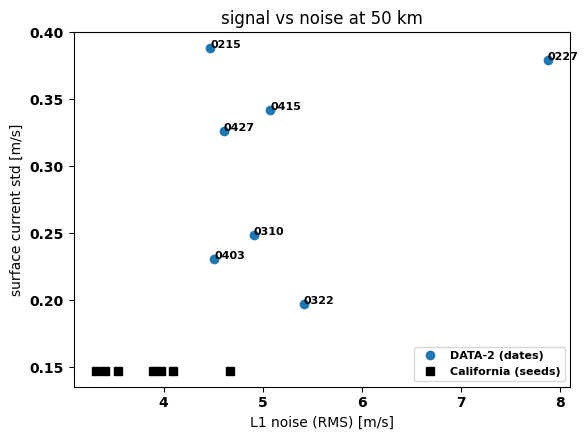

In [9]:
fig, ax = plt.subplots(figsize = (6, 4.5))
ax.plot(table_data_2["L1 noise RMS [m/s]"], table_data_2["TSC std [m/s]"], 'o', label = 'DATA-2 (dates)')
ax.plot(table_cali["L1 noise RMS [m/s]"], table_cali["TSC std [m/s]"], 'ks', label = 'California (seeds)')
for date in dates:
    ax.annotate(date[4:], (table_data_2.loc[date, "L1 noise RMS [m/s]"], table_data_2.loc[date, "TSC std [m/s]"]), fontsize = 8)
ax.set_xlabel("L1 noise (RMS) [m/s]")
ax.set_ylabel("surface current std [m/s]")
ax.set_title("signal vs noise at 50 km")
ax.legend(fontsize = 8)
plt.tight_layout()

## Maps
All DATA-2 dates (each with its own seed) and the reference simulation (seed 0): SCA NRCS, L1 noise and surface current at 50 km, the latter two on
their shared product cells (as in the summary). Note the different colour scale of the surface current.

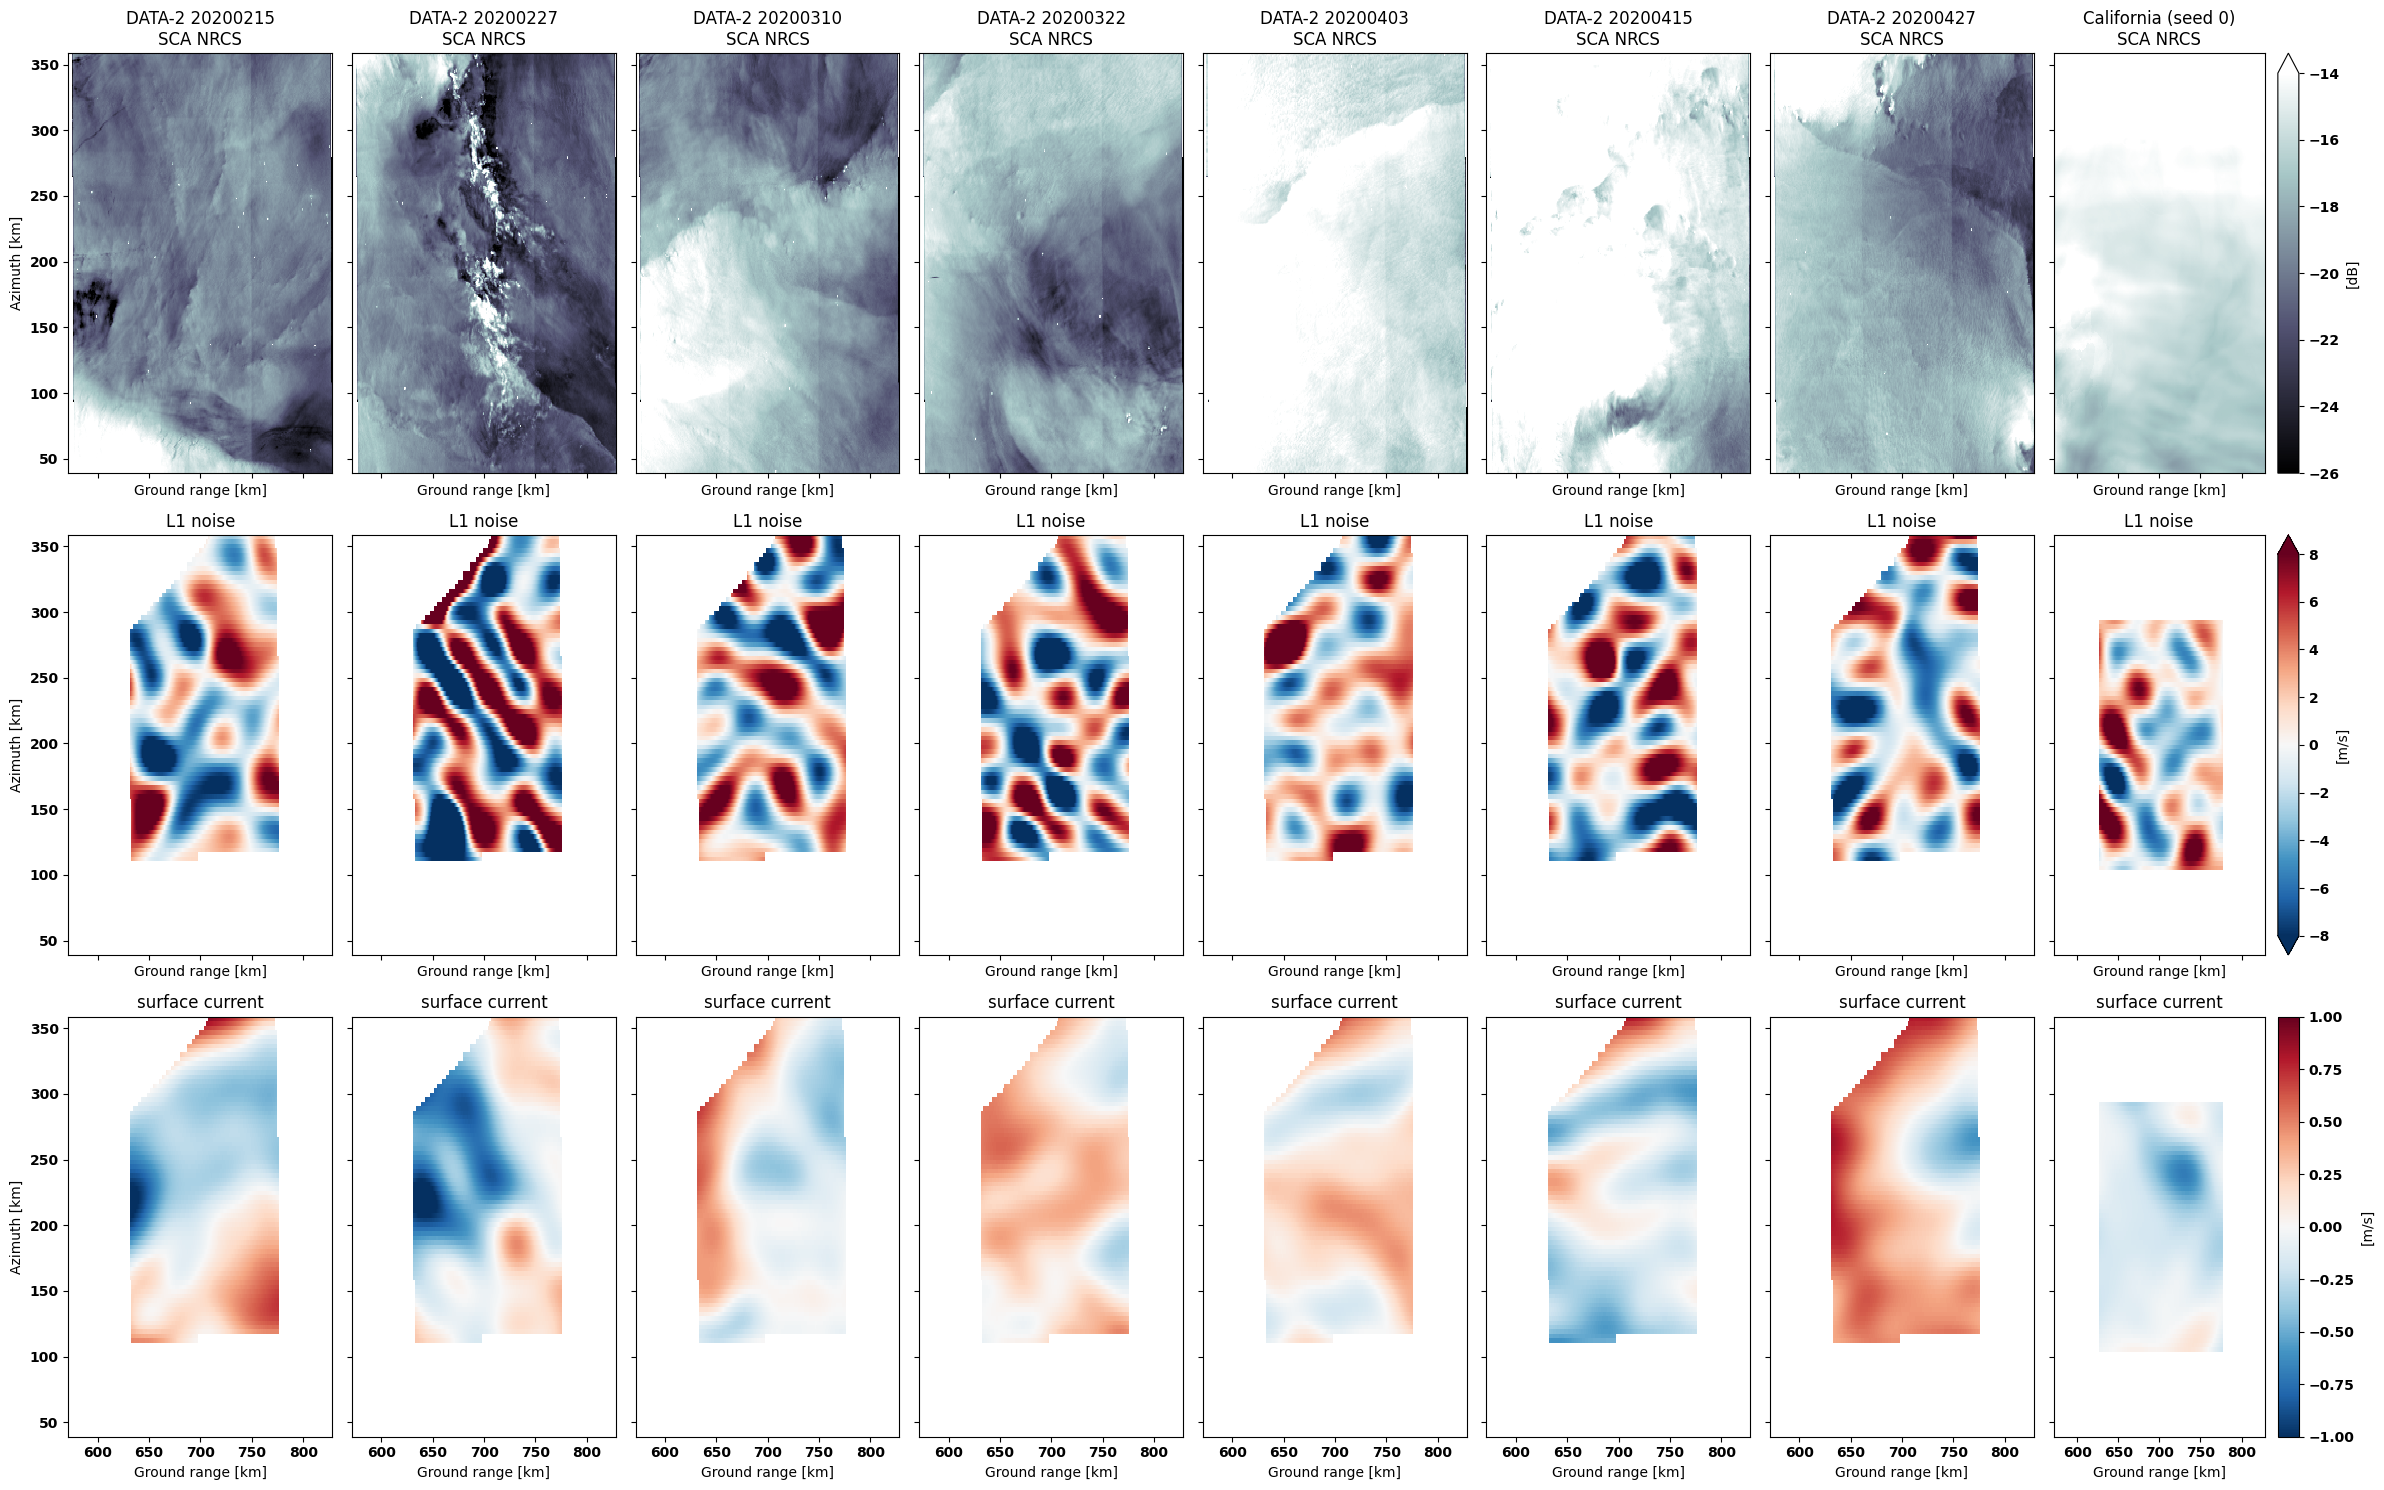

In [10]:
maps = {f"DATA-2 {date}": (scenes[date], ds_data_2[date]) for date in dates}
maps["California (seed 0)"] = (scene_cali, ds_cali)

fields = [("V_sigma_net_lpf", "L1 noise", 8), ("V_current_lpf", "surface current", 1)]
to_km = lambda da: da.assign_coords({name: da[name] / 1e3 for name in da.dims})

fig, axes = plt.subplots(ncols=len(maps), nrows=3, sharex=True, sharey=True, figsize = (3 * len(maps), 15))
for i, (title, (scene, ds)) in enumerate(maps.items()):
    last = i == len(maps) - 1
    (10 * np.log10(to_km(scene['nrcs']))).plot(ax = axes[0, i], x = 'grg', cmap = 'bone', vmin = -26, vmax = -14, add_colorbar = last, cbar_kwargs={"label": "[dB]"} if last else None)
    axes[0, i].set_title(f"{title}\nSCA NRCS")
    for ax, (name, label, vmax) in zip(axes[1:, i], fields):
        to_km(ds[name].where(shared_cells(ds))).plot(ax = ax, x = 'grg', cmap = 'RdBu_r', vmin = -vmax, vmax = vmax, add_colorbar = last, cbar_kwargs={"label": "[m/s]"} if last else None)
        ax.set_title(label)
    for ax in axes[:, i]:
        ax.set_xlabel("Ground range [km]")
        ax.set_ylabel("Azimuth [km]" if i == 0 else "")
plt.tight_layout()